# Session 30 Solutions: Hypothesis Testing

Data Science with Python, Level 2, Stage 4: Statistics

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(30)
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
ab = pd.read_csv(DATA_URL + "ab_test.csv")

## In-Class Exercises

### In-Class Exercise 1: Devices

In [2]:
table = pd.crosstab(ab["device"], ab["converted"])
print(table)
print(stats.chi2_contingency(table)[1])

converted  False  True 
device                 
Desktop     1333    201
Mobile      2192    274
0.06528614440186319


### In-Class Exercise 2: Pages Viewed

In [3]:
a = ab.loc[ab["group"] == "A", "pages_viewed"]
b = ab.loc[ab["group"] == "B", "pages_viewed"]
res = stats.ttest_ind(b, a, equal_var=False)
print(round(a.mean(), 2), round(b.mean(), 2), round(res.pvalue, 3))
print("Reject H0" if res.pvalue < 0.05 else "Do not reject H0")

3.19 3.15 0.303
Do not reject H0


### In-Class Exercise 3: Permutation on Time

In [4]:
t = ab["time_on_page_s"].to_numpy()
is_b = (ab["group"] == "B").to_numpy()
obs = t[is_b].mean() - t[~is_b].mean()
diffs = []
for _ in range(3000):
    s = rng.permutation(is_b)
    diffs.append(t[s].mean() - t[~s].mean())
print(round(obs, 2), (np.abs(diffs) >= abs(obs)).mean())

7.78 0.0


### In-Class Exercise 4: Sample Size Matters

In [5]:
small = ab.head(200)
print(pd.crosstab(small["group"], small["converted"]))
print(round(stats.chi2_contingency(pd.crosstab(small["group"], small["converted"]))[1], 3))

converted  False  True 
group                  
A             99     10
B             76     15
0.18


## Part A: Basic

### Exercise 1: State the Hypotheses

In [6]:
# 1. H0: the mean score is the same with both methods. H1: the means differ.
# 2. H0: P(heads) = 0.5. H1: P(heads) is not 0.5.
# 3. H0: churn is independent of the contract type. H1: churn depends on the contract type.
print(stats.binomtest(60, 100, 0.5).pvalue)

0.05688793364098089


### Exercise 2: Passed by Class

In [7]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
table = pd.crosstab(exams["class"], exams["passed"])
print(table)
print(round(stats.chi2_contingency(table)[1], 3))

passed  False  True 
class               
A          44     40
B          55     43
C          50     47
D          61     51
E          65     44
0.789


## Part B: Intermediate

### Exercise 3: Salaries of Two Cities

In [8]:
emp = pd.read_csv(DATA_URL + "employees.csv")
a = emp.loc[emp["city"] == "Amman", "monthly_salary"]
b = emp.loc[emp["city"] == "Beirut", "monthly_salary"]
res = stats.ttest_ind(a, b, equal_var=False)
d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print(round(a.mean()), round(b.mean()), round(res.pvalue, 3), round(d, 2))

2205 1987 0.009 0.38


### Exercise 4: More Than Two Groups

F_onewayResult(statistic=np.float64(125.75452129051806), pvalue=np.float64(1.2939005822327613e-65))


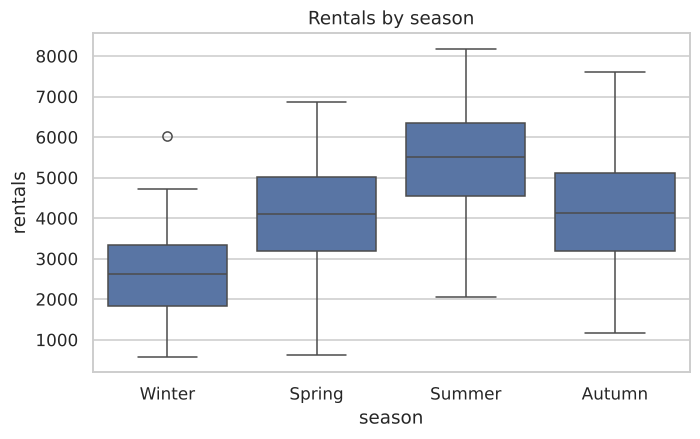

In [9]:
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
groups = [g["rentals"] for _, g in bikes.groupby("season")]
print(stats.f_oneway(*groups))
sns.boxplot(data=bikes, x="season", y="rentals", order=["Winter", "Spring", "Summer", "Autumn"])
plt.title("Rentals by season")
plt.show()

## Part C: Challenge

### Exercise 5: Power by Simulation

Small experiments usually miss a real two-point improvement. Planning the sample size before an experiment avoids wasted tests.

In [10]:
def power(n, pa=0.10, pb=0.12, runs=1000):
    hits = 0
    for _ in range(runs):
        ca, cb = rng.binomial(n, pa), rng.binomial(n, pb)
        table = [[ca, n - ca], [cb, n - cb]]
        hits += stats.chi2_contingency(table)[1] < 0.05
    return hits / runs

for n in [500, 2000, 5000]:
    print(n, power(n))

500 0.141
2000 0.487
5000 0.894


## Part D: Cumulative Project: Exam Scores Study

### Exercise 6: Exam Scores Study: Final Part

In [11]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
a = exams.loc[exams["sleep_hours"] >= 8, "math"]
b = exams.loc[exams["sleep_hours"] < 6, "math"]
res = stats.ttest_ind(a, b, equal_var=False)
d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print("Sleep:", round(a.mean(), 1), round(b.mean(), 1), round(res.pvalue, 4), round(d, 2))
table = pd.crosstab(exams["study_hours_week"] > 10, exams["passed"])
print("Study and passing p:", stats.chi2_contingency(table)[1])
print(stats.f_oneway(*[g["english"] for _, g in exams.groupby("class")]))
# Students who study more pass much more often, and study time is the habit most linked to good results.
# Students who sleep at least 8 hours score clearly higher in math than those who sleep less than 6.
# The five classes perform similarly, so the differences come from students' habits more than from their class.
# Limitation: this is observational data, so it shows associations, not proven causes.

Sleep: 60.8 53.5 0.0005 0.53
Study and passing p: 1.1199032785615308e-17
F_onewayResult(statistic=np.float64(0.3614109814565196), pvalue=np.float64(0.836083003155498))


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | H0 is the no-effect starting point. |
| 2 | B | The p-value is computed assuming H0 is true. |
| 3 | B | Both columns are categories, so use chi-square on the crosstab. |
| 4 | B | Large samples make tiny effects significant; report the effect size. |
| 5 | B | 5 percent of 20 tests is about 1 false alarm. |